# MPIIGaze - Exploratory Data Analysis

MPIIGaze (Zhang et al., CVPR 2015) contains 213,659 face images of 15 participants (p00-p14), captured by
their laptop webcams during everyday use over several months. We use the **normalized** eye patches
(36x60 grayscale, one per eye) together with the 3D gaze direction and head pose provided with the dataset.

Questions this notebook answers:
1. How is the data organized and how many samples does each participant contribute?
2. What do the eye images look like, and how much do lighting and appearance vary?
3. What range of gaze directions and head poses is covered, and how do they relate?
4. Is the standard evaluation subset (3000 eyes per person) representative of the full data?
5. What does this imply for the training pipeline?

In [1]:
import sys, os
sys.path.append(os.path.join(os.pardir, os.pardir))  # repository root: common/ and mpiigaze/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpiigaze import dataset, plot_style
from mpiigaze.plot_style import BLUE, ORANGE, AQUA, SEQ_CMAP, TEXT2
plot_style.apply()
FIG_DIR = os.path.join(os.pardir, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

meta = dataset.load_meta()        # every normalized eye sample (labels + image statistics)
ev = dataset.load_eval_subset()   # standard evaluation subset (with images)
P = dataset.PERSONS
deg = np.degrees

## 1. Dataset structure

`Data/Normalized/pXX/dayYY.mat` holds one recording day per file. Each file contains, for the left and right eye,
`image` (N x 36 x 60, uint8), `gaze` (N x 3 unit vector in the normalized camera space) and `pose`
(N x 3 head rotation vector). We convert both vectors to **(pitch, yaw)** angles.

In [2]:
df = pd.DataFrame({'person': np.array(P)[meta['person']], 'day': meta['day'],
                   'side': np.where(meta['side'] == 0, 'left', 'right'),
                   'gaze_pitch': deg(meta['gaze'][:, 0]), 'gaze_yaw': deg(meta['gaze'][:, 1]),
                   'pose_pitch': deg(meta['pose'][:, 0]), 'pose_yaw': deg(meta['pose'][:, 1]),
                   'img_mean': meta['img_mean'], 'img_std': meta['img_std']})
summary = df[df.side == 'left'].groupby('person').agg(days=('day', 'nunique'), images=('day', 'size'))
summary['eye samples'] = summary['images'] * 2
print('total face images  :', summary['images'].sum())
print('total eye samples  :', len(df))
print('evaluation subset  :', len(ev['person']), 'eyes (', np.bincount(ev['side']).tolist(), 'left/right )')
summary.T

total face images  : 213658
total eye samples  : 427316
evaluation subset  : 45000 eyes ( [22500, 22500] left/right )


person,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14
days,39,69,39,65,25,38,62,56,47,20,16,19,7,12,7
images,29961,24143,28019,35075,16831,16577,18448,15509,10701,7995,2810,2982,1609,1498,1500
eye samples,59922,48286,56038,70150,33662,33154,36896,31018,21402,15990,5620,5964,3218,2996,3000


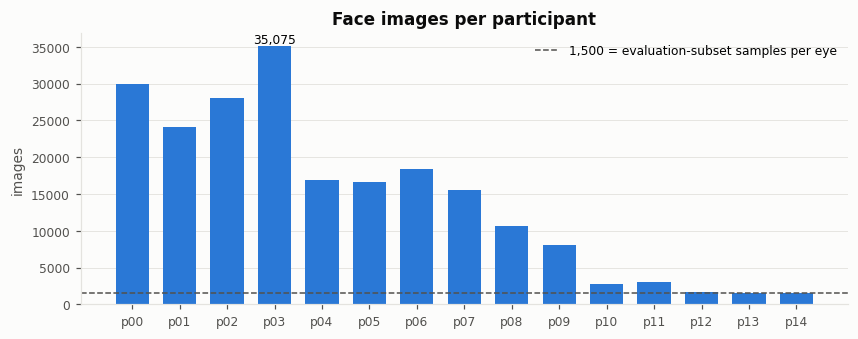

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(summary.index, summary['images'], color=BLUE, width=0.7)
ax.axhline(1500, color=TEXT2, lw=1, ls='--', label='1,500 = evaluation-subset samples per eye')
ax.legend(loc='upper right')
for i, v in enumerate(summary['images']):
    if i == summary['images'].values.argmax():
        ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
ax.set_title('Face images per participant')
ax.set_ylabel('images'); ax.grid(axis='x', visible=False)
fig.savefig(os.path.join(FIG_DIR, 'samples_per_person.png')); plt.show()

The number of images is highly unbalanced across participants (p03 has ~23x more than p12). Recording length also differs:

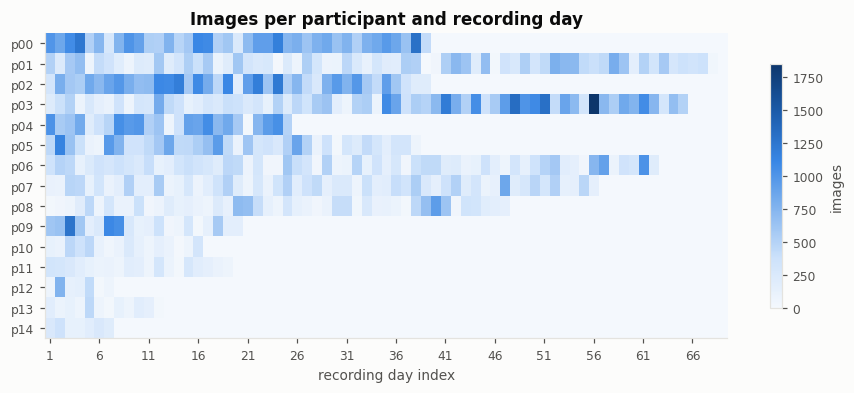

In [4]:
counts = df[df.side == 'left'].pivot_table(index='person', columns='day', values='img_mean', aggfunc='size').fillna(0)
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(counts.values, aspect='auto', cmap=SEQ_CMAP, interpolation='nearest')
ax.set_yticks(range(len(counts.index))); ax.set_yticklabels(counts.index)
ax.set_xticks(range(0, counts.shape[1], 5)); ax.set_xticklabels(counts.columns[::5])
ax.set_xlabel('recording day index'); ax.set_title('Images per participant and recording day'); ax.grid(False)
fig.colorbar(im, ax=ax, label='images', shrink=0.8); plt.show()

## 2. What the eye images look like

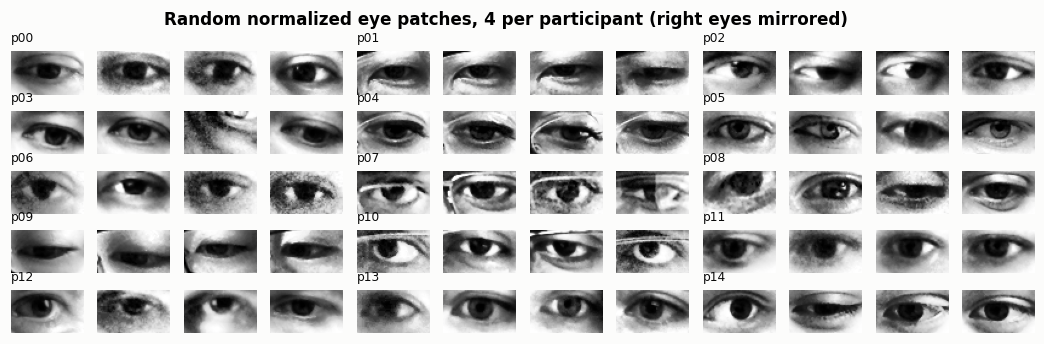

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(5, 12, figsize=(12, 3.4))
for k, ax in enumerate(axes.flat):
    p = k // 4
    idx = rng.choice(np.where(ev['person'] == p)[0])
    ax.imshow(ev['image'][idx], cmap='gray', vmin=0, vmax=255)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    if k % 4 == 0: ax.set_title(P[p], fontsize=8, loc='left', fontweight='normal')
fig.suptitle('Random normalized eye patches, 4 per participant (right eyes mirrored)', fontsize=11, fontweight='bold')
fig.savefig(os.path.join(FIG_DIR, 'eye_samples.png')); plt.show()

Appearance varies a lot between participants (eye shape, eyeglasses, blur, shadows). Global brightness and
contrast, however, look surprisingly uniform. Per-image intensity statistics confirm it:

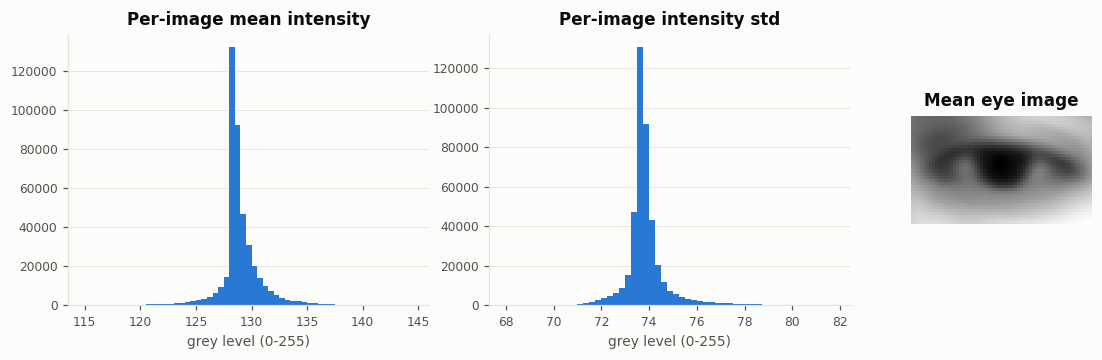

(x-axes clipped to the central range; full range below)
             count   mean  std   min    25%    50%    75%    max
img_mean  427316.0  128.9  2.3  40.6  128.3  128.6  129.5  219.9
img_std   427316.0   73.9  1.1  60.9   73.5   73.7   74.0  101.4


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={'width_ratios': [2, 2, 1]})
axes[0].hist(df.img_mean, bins=np.arange(115, 145, 0.5), color=BLUE); axes[0].set_title('Per-image mean intensity')
axes[1].hist(df.img_std, bins=np.arange(68, 82, 0.25), color=BLUE); axes[1].set_title('Per-image intensity std')
for ax in axes[:2]: ax.set_xlabel('grey level (0-255)'); ax.grid(axis='x', visible=False)
axes[2].imshow(meta['mean_image'], cmap='gray'); axes[2].set_title('Mean eye image'); axes[2].axis('off')
fig.savefig(os.path.join(FIG_DIR, 'intensity.png')); plt.show()
print('(x-axes clipped to the central range; full range below)')
print(df[['img_mean', 'img_std']].describe().round(1).T)

Every patch has mean ~128 and std ~74 - the signature of **histogram-equalized** images (a uniform
0-255 histogram has mean 127.5 and std 73.9). The dataset authors already equalized the normalized patches.
Equalizing again is effectively a no-op:

In [7]:
sample = ev['image'][:5000]
diff = np.abs(dataset.equalize_hist(sample).astype(int) - sample).mean()
print('mean |equalize(x) - x| = %.3f grey levels' % diff)

mean |equalize(x) - x| = 0.078 grey levels


## 3. Gaze direction and head pose

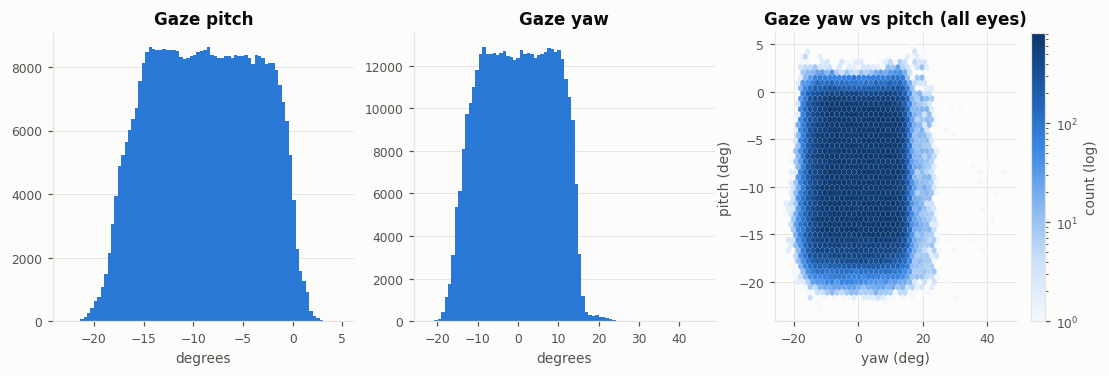

,gaze_pitch,gaze_yaw,pose_pitch,pose_yaw
count,427316.00,427316.00,427316.00,427316.00
mean,-8.80,0.00,11.59,0.82
std,5.22,8.61,13.71,9.17
min,-22.76,-22.45,-44.11,-53.11
25%,-13.15,-7.18,2.15,-4.54
50%,-8.79,0.07,9.53,0.79
75%,-4.40,7.29,22.31,5.62
max,4.76,45.42,58.56,55.29


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, name in [(axes[0], 'gaze_pitch', 'Gaze pitch'), (axes[1], 'gaze_yaw', 'Gaze yaw')]:
    ax.hist(df[col], bins=80, color=BLUE)
    ax.set_title(name); ax.set_xlabel('degrees'); ax.grid(axis='x', visible=False)
hb = axes[2].hexbin(df.gaze_yaw, df.gaze_pitch, gridsize=45, cmap=SEQ_CMAP, mincnt=1, bins='log')
axes[2].set_xlabel('yaw (deg)'); axes[2].set_ylabel('pitch (deg)'); axes[2].set_title('Gaze yaw vs pitch (all eyes)')
fig.colorbar(hb, ax=axes[2], label='count (log)')
fig.savefig(os.path.join(FIG_DIR, 'gaze_distribution.png')); plt.show()
df[['gaze_pitch', 'gaze_yaw', 'pose_pitch', 'pose_yaw']].describe().round(2)

Gaze is concentrated in a narrow cone that matches a laptop screen: pitch mostly between -20 and 5 degrees
(looking slightly down at the screen), yaw within about +-20 degrees. Every participant covers a different part of this range:

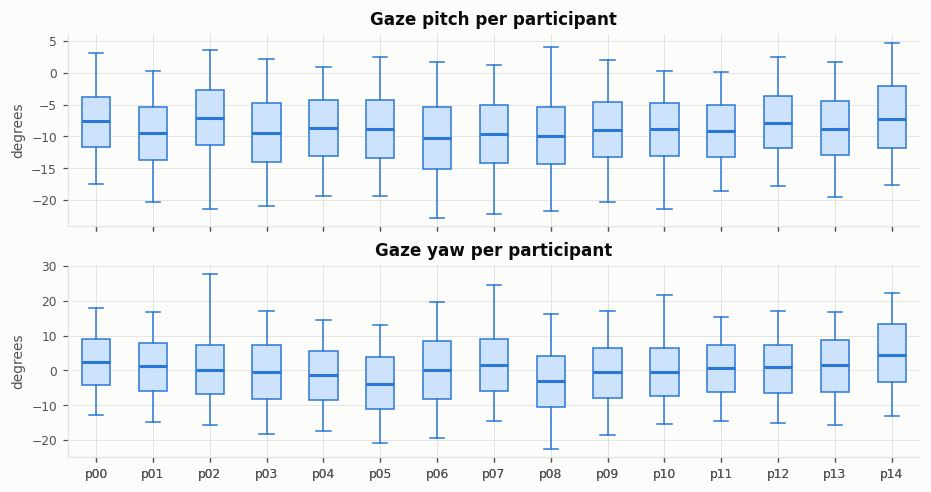

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, col, name in [(axes[0], 'gaze_pitch', 'Gaze pitch'), (axes[1], 'gaze_yaw', 'Gaze yaw')]:
    ax.boxplot([df.loc[df.person == p, col].values for p in P], tick_labels=P, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor='#cde2fb', color=BLUE), medianprops=dict(color=BLUE, lw=2),
               whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
    ax.set_ylabel('degrees'); ax.set_title(name + ' per participant')
fig.savefig(os.path.join(FIG_DIR, 'gaze_per_person.png')); plt.show()

**Left vs. right eye.** The paper mirrors right-eye patches (and negates yaw) so that one network sees
only "left-looking" eyes. The yaw distributions of both eyes are already centred at 0, so mirroring matters for
*appearance* (position of the inner/outer eye corner), not for the label distribution.

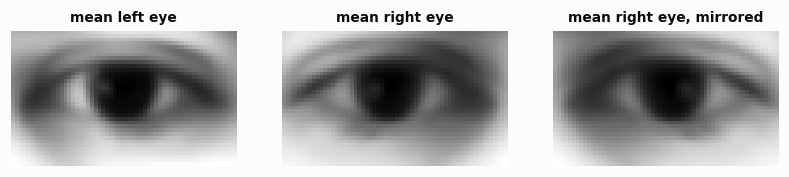

pixel correlation  left vs right: 0.829   left vs mirrored right: 0.837
mean gaze yaw  left: 0.05 deg   right: -0.04 deg


In [10]:
names, data = dataset._read_day(os.path.join(dataset.NORM_DIR, 'p00', 'day01.mat'))
L, R = data['left'][0].mean(0), data['right'][0].mean(0)
fig, axes = plt.subplots(1, 3, figsize=(9, 1.9))
for ax, img, t in zip(axes, (L, R, R[:, ::-1]), ('mean left eye', 'mean right eye', 'mean right eye, mirrored')):
    ax.imshow(img, cmap='gray'); ax.set_title(t, fontsize=9); ax.axis('off')
plt.show()
corr = lambda a, b: np.corrcoef(a.ravel(), b.ravel())[0, 1]
print('pixel correlation  left vs right: %.3f   left vs mirrored right: %.3f' % (corr(L, R), corr(L, R[:, ::-1])))
print('mean gaze yaw  left: %.2f deg   right: %.2f deg' % (df[df.side == 'left'].gaze_yaw.mean(), df[df.side == 'right'].gaze_yaw.mean()))

**Head pose** - its range is wider than the gaze range. How strongly is gaze tied to head pose?

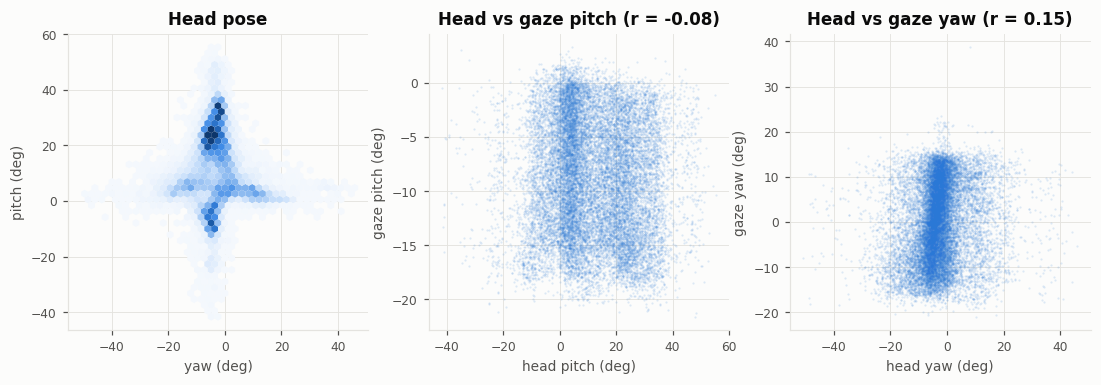

,gaze_pitch,gaze_yaw,pose_pitch,pose_yaw,img_mean
gaze_pitch,1.00,0.01,-0.09,0.04,-0.01
gaze_yaw,0.01,1.00,-0.04,0.14,0.04
pose_pitch,-0.09,-0.04,1.00,-0.01,0.05
pose_yaw,0.04,0.14,-0.01,1.00,-0.01
img_mean,-0.01,0.04,0.05,-0.01,1.00


In [11]:
sub = df[df.side == 'left'].sample(20000, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
hb = axes[0].hexbin(sub.pose_yaw, sub.pose_pitch, gridsize=40, cmap=SEQ_CMAP, mincnt=1)
axes[0].set_xlabel('yaw (deg)'); axes[0].set_ylabel('pitch (deg)'); axes[0].set_title('Head pose')
for ax, a in ((axes[1], 'pitch'), (axes[2], 'yaw')):
    ax.scatter(sub['pose_' + a], sub['gaze_' + a], s=2, alpha=0.15, color=BLUE, linewidths=0)
    r = np.corrcoef(sub['pose_' + a], sub['gaze_' + a])[0, 1]
    ax.set_xlabel('head %s (deg)' % a); ax.set_ylabel('gaze %s (deg)' % a)
    ax.set_title('Head vs gaze %s (r = %.2f)' % (a, r))
plt.show()
df[['gaze_pitch', 'gaze_yaw', 'pose_pitch', 'pose_yaw', 'img_mean']].corr().round(2)

## 4. Evaluation subset vs. full data

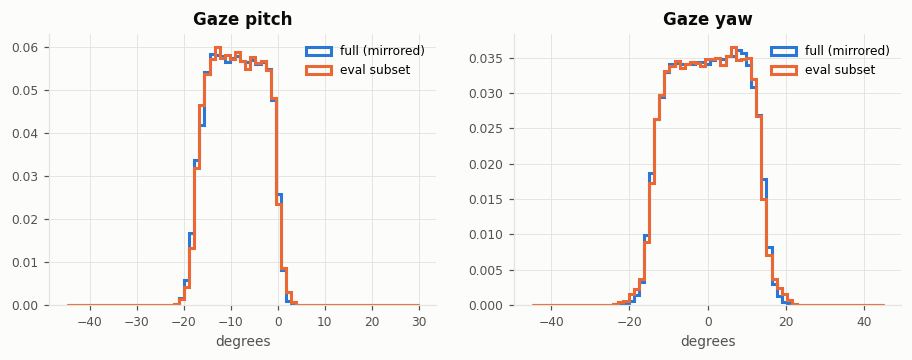

,full mean,eval mean,eval std
pitch,-8.80,-8.75,5.20
yaw,0.05,0.03,8.69


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
full_l = df[df.side == 'left']
full_r = df[df.side == 'right']
for ax, k, name in ((axes[0], 0, 'pitch'), (axes[1], 1, 'yaw')):
    full = np.concatenate([full_l['gaze_' + name], full_r['gaze_' + name] * (-1 if k == 1 else 1)])
    bins = np.linspace(-45, 30, 70) if k == 0 else np.linspace(-45, 45, 70)
    ax.hist(full, bins=bins, density=True, histtype='step', lw=2, color=BLUE, label='full (mirrored)')
    ax.hist(deg(ev['gaze'][:, k]), bins=bins, density=True, histtype='step', lw=2, color=ORANGE, label='eval subset')
    ax.set_title('Gaze ' + name); ax.set_xlabel('degrees'); ax.legend()
plt.show()
cmp = pd.DataFrame({'full mean': [full_l.gaze_pitch.mean(), 0.5 * (full_l.gaze_yaw.mean() - full_r.gaze_yaw.mean())],
                    'eval mean': deg(ev['gaze'].mean(0)), 'eval std': deg(ev['gaze'].std(0))}, index=['pitch', 'yaw'])
cmp.round(2)

## 5. Data quality checks

In [13]:
print('NaN in labels        :', int(np.isnan(meta['gaze']).sum() + np.isnan(meta['pose']).sum()))
print('NaN in eval subset   :', int(np.isnan(ev['gaze']).sum() + np.isnan(ev['pose']).sum()))
print('near-black images    : %d (mean < 10)' % (df.img_mean < 10).sum())
print('near-flat images     : %d (std < 5)' % (df.img_std < 5).sum())
print('extreme gaze (>45deg): %d' % ((df.gaze_pitch.abs() > 45) | (df.gaze_yaw.abs() > 45)).sum())
flat = ev['image'].reshape(len(ev['image']), -1)
_, uniq = np.unique(flat, axis=0, return_index=True)
print('duplicate eval images:', len(flat) - len(uniq))

NaN in labels        : 0
NaN in eval subset   : 0
near-black images    : 0 (mean < 10)
near-flat images     : 0 (std < 5)
extreme gaze (>45deg): 1


duplicate eval images: 4


## 6. Findings and implications for the pipeline

| # | Observation | Implication for the pipeline |
|---|---|---|
| 1 | 213,658 face images / 427,316 eye patches from 15 people, **heavily unbalanced** (p03: 35,075 images over 65 days; p13: 1,498 images over 12 days). | Train on the standard **evaluation subset** (3,000 eyes per person) so no participant dominates. |
| 2 | Gaze covers a narrow, screen-shaped range: pitch -22.8 to 4.8 deg (mean -8.8, sd 5.2), yaw about +-22 deg (sd 8.6). | Regress (pitch, yaw) directly in radians. A constant "mean gaze" predictor is already ~8-10 deg off, so it is the **baseline** to beat. |
| 3 | Each participant has their own gaze distribution (median pitch -7 to -10 deg, median yaw -4 to +4 deg) and appearance (glasses, eye shape, blur). | The hard problem is generalizing to **unseen people**: evaluate with **leave-one-person-out**. |
| 4 | Head pose varies more than gaze (pitch sd 13.7 deg), but in normalized space it is only weakly correlated with gaze (r = -0.09 pitch, 0.14 yaw). | Head pose alone cannot predict gaze; the eye image carries the signal. Feed pose as an **auxiliary input** next to the CNN features (and ablate it). |
| 5 | Every patch has mean ~128 and std ~74: the normalized images are **already histogram-equalized**. | No extra equalization; just scale pixels to [0, 1]. |
| 6 | Left/right eyes have the same label distribution; mirroring right eyes mainly aligns appearance. | Mirror right eyes (as in the paper) so one network handles both eyes. |
| 7 | The evaluation subset matches the full data (pitch mean -8.75 vs -8.80 deg). No NaNs, no black or flat images; 1 sample beyond 45 deg, 4 duplicate patches. | The subset is representative and clean enough to use as is. |